# Revisited analysis: summary

This notebook only reads the files written by `run_experiments.py` and `run_bootstrap.py`; it trains nothing.
It answers four questions left open by the thesis:

1. What does XGBSE score once its hyperparameter search really changes the model?
2. How uncertain are the metrics on a test set of 132 patients?
3. How do the models compare when they all use the same train/test split?
4. How much of the performance comes from treatment and intent variables?

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from survml.common import FEATURE_SET_LABELS, RESULTS_DIR
from survml.models import MODELS

pd.set_option("display.width", 200)
FIGURES = RESULTS_DIR / "figures"
FIGURES.mkdir(exist_ok=True)

summary = pd.read_csv(RESULTS_DIR / "summary.csv")
paired = pd.read_csv(RESULTS_DIR / "paired_vs_rsf.csv")
effect = pd.read_csv(RESULTS_DIR / "feature_set_effect.csv")
MODEL_ORDER = list(MODELS)
LABELS = {name: label for name, (label, _) in MODELS.items()}
METRIC_NAMES = {"c_index": "C-index", "ibs": "IBS", "auc_1y": "AUC 1 y", "auc_3y": "AUC 3 y",
                "auc_5y": "AUC 5 y", "auc_mean": "Mean AUC"}


def table(feature_set):
    """Point estimate and 95% bootstrap interval of every metric for one feature set."""
    rows = summary[summary.feature_set == feature_set].copy()
    rows["value"] = rows.apply(lambda r: f"{r.estimate:.3f} ({r.ci_low:.3f}-{r.ci_high:.3f})", axis=1)
    wide = rows.pivot(index="model", columns="metric", values="value").loc[MODEL_ORDER, list(METRIC_NAMES)]
    return wide.rename(index=LABELS, columns=METRIC_NAMES)

## 1. All features, one split, with confidence intervals

Every model is trained and tested on the same patients (seed 25, the split the thesis used for RSF and XGBSE).
Intervals are 95% percentile intervals from 1,000 bootstrap resamples of the test set. They describe the
uncertainty due to the small test set, not the variability of training.

In [2]:
table("full")

metric,C-index,IBS,AUC 1 y,AUC 3 y,AUC 5 y,Mean AUC
model,,,,,,
Cox PH (ridge),0.707 (0.642-0.770),0.189 (0.157-0.221),0.747 (0.647-0.837),0.749 (0.631-0.857),0.728 (0.571-0.867),0.741 (0.652-0.826)
Random Survival Forest,0.735 (0.665-0.807),0.194 (0.166-0.222),0.768 (0.676-0.856),0.786 (0.673-0.891),0.790 (0.658-0.903),0.781 (0.699-0.860)
XGBSE (tuned),0.676 (0.597-0.751),0.224 (0.178-0.274),0.710 (0.593-0.818),0.722 (0.606-0.824),0.639 (0.479-0.783),0.690 (0.592-0.780)
XGBSE (library defaults),0.707 (0.636-0.775),0.181 (0.141-0.222),0.713 (0.590-0.831),0.759 (0.646-0.862),0.759 (0.618-0.878),0.744 (0.653-0.827)
DeepSurv (5 runs),0.688 (0.628-0.747),0.194 (0.161-0.227),0.728 (0.624-0.812),0.721 (0.623-0.818),0.698 (0.562-0.826),0.716 (0.637-0.797)


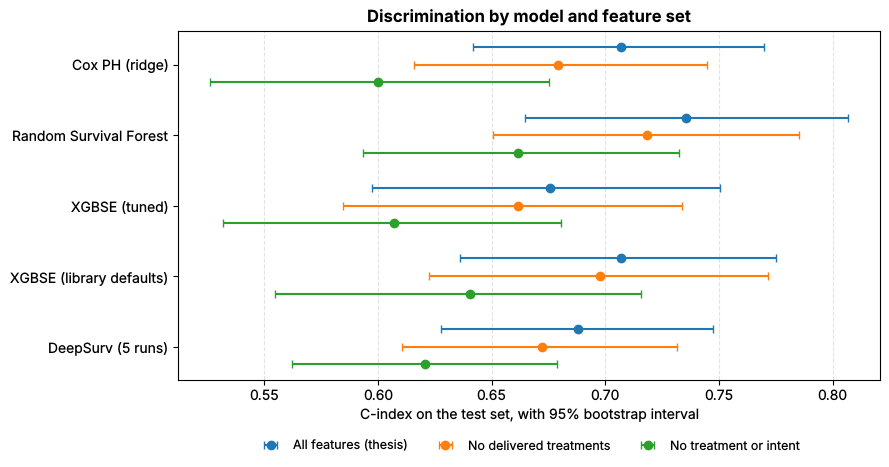

In [3]:
def interval_plot(metric, title, filename):
    fig, ax = plt.subplots(figsize=(9, 4.8))
    feature_sets = list(FEATURE_SET_LABELS)
    offsets = np.linspace(-0.25, 0.25, len(feature_sets))
    colors = ["#1f77b4", "#ff7f0e", "#2ca02c"]
    for offset, feature_set, color in zip(offsets, feature_sets, colors):
        rows = summary[(summary.metric == metric) & (summary.feature_set == feature_set)].set_index("model").loc[MODEL_ORDER]
        y = np.arange(len(MODEL_ORDER)) + offset
        ax.errorbar(rows.estimate, y, xerr=[rows.estimate - rows.ci_low, rows.ci_high - rows.estimate],
                    fmt="o", color=color, capsize=3, label=FEATURE_SET_LABELS[feature_set])
    ax.set_yticks(np.arange(len(MODEL_ORDER)), [LABELS[m] for m in MODEL_ORDER])
    ax.invert_yaxis()
    ax.set_xlabel(f"{METRIC_NAMES[metric]} on the test set, with 95% bootstrap interval")
    ax.set_title(title, fontweight="bold")
    ax.grid(axis="x", alpha=0.35, linestyle="--")
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=3, fontsize=9, frameon=False)
    fig.tight_layout()
    fig.savefig(FIGURES / filename, dpi=150)
    plt.show()


interval_plot("c_index", "Discrimination by model and feature set", "c_index_intervals.png")

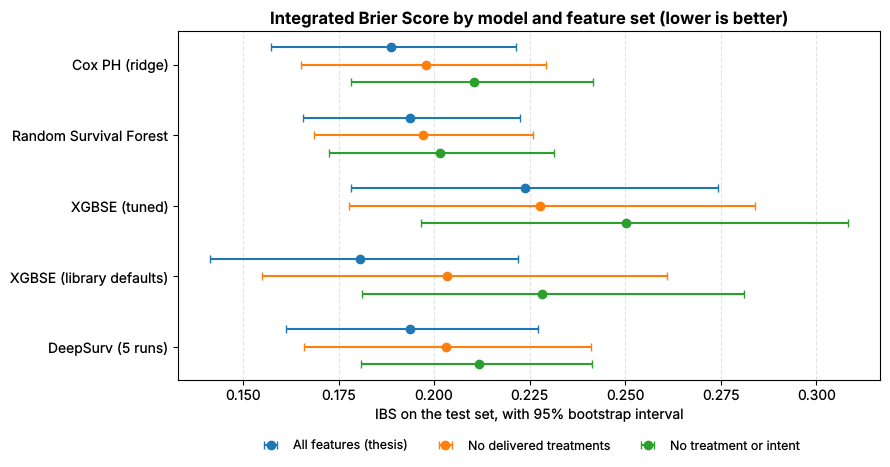

In [4]:
interval_plot("ibs", "Integrated Brier Score by model and feature set (lower is better)", "ibs_intervals.png")

## 2. Are the differences between models real?

Paired bootstrap differences from the Random Survival Forest: the same resampled patients are scored by both
models, and the table reports model minus RSF. A difference is flagged only when its 95% interval excludes zero.

In [5]:
def difference_table(frame, index_col, feature_set=None, metrics=("c_index", "ibs", "auc_mean")):
    rows = frame if feature_set is None else frame[frame.feature_set == feature_set]
    rows = rows[rows.metric.isin(metrics)].copy()
    rows["value"] = rows.apply(lambda r: f"{r.difference:+.3f} ({r.ci_low:+.3f} to {r.ci_high:+.3f})" + (" *" if r.excludes_zero else ""), axis=1)
    return rows.pivot(index=index_col, columns="metric", values="value")[list(metrics)].rename(columns=METRIC_NAMES)


difference_table(paired, "model", "full").rename(index=LABELS)

metric,C-index,IBS,Mean AUC
model,,,
Cox PH (ridge),-0.028 (-0.085 to +0.027),-0.005 (-0.019 to +0.009),-0.040 (-0.110 to +0.029)
DeepSurv (5 runs),-0.047 (-0.110 to +0.010),+0.000 (-0.015 to +0.017),-0.065 (-0.139 to +0.004)
XGBSE (tuned),-0.060 (-0.126 to +0.001),+0.030 (-0.003 to +0.064),-0.091 (-0.179 to -0.004) *
XGBSE (library defaults),-0.028 (-0.098 to +0.041),-0.013 (-0.042 to +0.016),-0.038 (-0.124 to +0.044)


## 3. XGBSE: what the search does once it works

In the thesis all 150 configurations trained the same default model. With the wrapper in `survml/models.py`
each configuration is a different model, so the cross-validation scores now differ.

In [6]:
rows = []
for feature_set in FEATURE_SET_LABELS:
    tuned = json.loads((RESULTS_DIR / f"metrics__{feature_set}__xgbse.json").read_text())
    default = json.loads((RESULTS_DIR / f"metrics__{feature_set}__xgbse_default.json").read_text())
    info = tuned["info"]
    rows.append({"feature set": FEATURE_SET_LABELS[feature_set],
                 "distinct CV scores (of 150)": info["distinct_cv_scores"],
                 "best CV C-index": round(info["cv_c_index"], 4),
                 "train C-index, tuned": round(info["train_c_index"], 4),
                 "test C-index, tuned": round(tuned["metrics"]["c_index"], 4),
                 "train C-index, defaults": round(default["info"]["train_c_index"], 4),
                 "test C-index, defaults": round(default["metrics"]["c_index"], 4)})
pd.DataFrame(rows).set_index("feature set")

,distinct CV scores (of 150),best CV C-index,"train C-index, tuned","test C-index, tuned","train C-index, defaults","test C-index, defaults"
feature set,,,,,,
All features (thesis),137,0.6697,0.7765,0.6758,0.9130,0.7070
No delivered treatments,137,0.6738,0.7673,0.6614,0.9131,0.6978
No treatment or intent,128,0.6357,0.7950,0.6071,0.9120,0.6403


## 4. How much do treatment and intent variables contribute?

Three feature sets, same patients:

- **All features**: the 33 features of the thesis.
- **No delivered treatments**: without `Trt_PHARMACEUTICAL`, `Trt_RADIATION`, `Trt_SURGERY` and `Intent_ADJUVANT`,
  which describe care given after diagnosis.
- **No treatment or intent**: demographics, tumour and exposure only, that is what is known at diagnosis before
  any therapeutic decision.

In [7]:
pd.concat({FEATURE_SET_LABELS[fs]: table(fs)[["C-index", "IBS", "Mean AUC"]] for fs in FEATURE_SET_LABELS}, axis=1)

All features (thesis)                                           No delivered treatments                                           No treatment or intent  \
metric                                 C-index                  IBS             Mean AUC                 C-index                  IBS             Mean AUC                C-index   
model                                                                                                                                                                               
Cox PH (ridge)             0.707 (0.642-0.770)  0.189 (0.157-0.221)  0.741 (0.652-0.826)     0.679 (0.616-0.745)  0.198 (0.165-0.229)  0.703 (0.613-0.792)    0.600 (0.526-0.675)   
Random Survival Forest     0.735 (0.665-0.807)  0.194 (0.166-0.222)  0.781 (0.699-0.860)     0.718 (0.651-0.785)  0.197 (0.169-0.226)  0.764 (0.674-0.847)    0.661 (0.593-0.733)   
XGBSE (tuned)              0.676 (0.597-0.751)  0.224 (0.178-0.274)  0.690 (0.592-0.780)     0.661 (0.584-0.734)  0.228 (0.178-0.284)  0.645 (0.538-0.744)    0.607 (0.532-0.681)   
XGBSE (library defaults)   0.707 (0.636-0.775)  0.181 (0.141-0.222)  0.744 (0.653-0.827)     0.698 (0.622-0.772)  0.203 (0.155-0.261)  0.705 (0.595-0.804)    0.640 (0.555-0.715)   
DeepSurv (5 runs)          0.688 (0.628-0.747)  0.194 (0.161-0.227)  0.716 (0.637-0.797)     0.672 (0.611-0.732)  0.203 (0.166-0.241)  0.689 (0.603-0.776)    0.621 (0.562-0.679)   

                                                                    
metric                                    IBS             Mean AUC  
model                                                               
Cox PH (ridge)            0.210 (0.178-0.242)  0.628 (0.529-0.725)  
Random Survival Forest    0.202 (0.173-0.231)  0.716 (0.626-0.799)  
XGBSE (tuned)             0.250 (0.196-0.308)  0.642 (0.544-0.737)  
XGBSE (library defaults)  0.228 (0.181-0.281)  0.653 (0.541-0.755)  
DeepSurv (5 runs)         0.212 (0.181-0.241)  0.638 (0.557-0.720)

Change of each model relative to its own all-features version (paired bootstrap, reduced set minus full set):

In [8]:
out = {}
for feature_set in ("no_treatment", "baseline"):
    out[FEATURE_SET_LABELS[feature_set]] = difference_table(effect, "model", feature_set, metrics=("c_index", "ibs")).loc[MODEL_ORDER].rename(index=LABELS)
pd.concat(out, axis=1)

No delivered treatments                                    No treatment or intent                             
metric                                        C-index                          IBS                      C-index                          IBS
model                                                                                                                                       
Cox PH (ridge)            -0.028 (-0.053 to -0.005) *  +0.009 (+0.003 to +0.016) *  -0.107 (-0.171 to -0.044) *  +0.022 (+0.007 to +0.036) *
Random Survival Forest      -0.017 (-0.044 to +0.010)    +0.003 (-0.001 to +0.007)  -0.074 (-0.122 to -0.027) *  +0.008 (+0.000 to +0.015) *
XGBSE (tuned)               -0.014 (-0.067 to +0.032)    +0.004 (-0.024 to +0.035)  -0.069 (-0.142 to -0.000) *    +0.026 (-0.011 to +0.068)
XGBSE (library defaults)    -0.009 (-0.056 to +0.036)    +0.023 (-0.012 to +0.059)    -0.067 (-0.143 to +0.011)  +0.048 (+0.008 to +0.087) *
DeepSurv (5 runs)           -0.016 (-0.044 to +0.011)    +0.009 (-0.001 to +0.021)  -0.068 (-0.112 to -0.017) *  +0.018 (+0.002 to +0.035) *

## 5. Against the numbers of the thesis

RSF and the default XGBSE use the same split as in the thesis, so their values should match it; DeepSurv moves
from seed 26 to seed 25 and its preprocessing is refitted in every run.

In [9]:
thesis = pd.DataFrame({"C-index": [0.7363, 0.7070, 0.7056], "IBS": [0.1923, 0.1806, 0.1963], "Mean AUC": [0.7844, 0.7441, 0.7015]},
                      index=["rsf", "xgbse_default", "deepsurv"])
now = summary[(summary.feature_set == "full") & summary.metric.isin(["c_index", "ibs", "auc_mean"])].pivot(index="model", columns="metric", values="estimate")
now = now.rename(columns=METRIC_NAMES).loc[thesis.index, thesis.columns]
pd.concat({"thesis": thesis, "revisited": now.round(4)}, axis=1).rename(index=LABELS)

thesis                  revisited                 
                         C-index     IBS Mean AUC   C-index     IBS Mean AUC
Random Survival Forest    0.7363  0.1923   0.7844    0.7354  0.1936   0.7814
XGBSE (library defaults)  0.7070  0.1806   0.7441    0.7070  0.1806   0.7437
DeepSurv (5 runs)         0.7056  0.1963   0.7015    0.6882  0.1938   0.7159